# Phase I – Behavior analysis (Pair B)
Ladder: **what → where → why → is it stable?** Every section starts with the question its plot answers.
Data: `predictions.csv` (long format, one row per image × model × perturbation × level × prompt_set). A *condition* = perturbation family + level (24 incl. clean, i.e. 23 perturbed conditions).

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = '../outputs/predictions.csv'
SPLIT = 'test'
CLIP_PROMPT_SET = 'ensemble'   # plain, steel, defect, ensemble

df = pd.read_csv(DATA_PATH)
df = df[df['split'] == SPLIT].copy()
df['correct'] = (df['true_class'] == df['pred_class']).astype(int)
# one condition = perturbation family + level (e.g. blur_2.0); 'clean' has level 0
df['cond'] = df['perturbation'] + '_' + df['level'].astype(str).str.replace(r'\.0$', '', regex=True)
df.loc[df['perturbation'] == 'clean', 'cond'] = 'clean'
cond_order = (df[['cond', 'perturbation', 'level']].drop_duplicates()
              .sort_values(['perturbation', 'level'])['cond'].tolist())
cond_order.remove('clean'); cond_order = ['clean'] + cond_order

# Sanity checks: fail loudly instead of silently skipping plots
need = {'perturbation','split','model','prompt_set','image','true_class','pred_class','confidence'}
assert need <= set(df.columns), f'missing columns: {need - set(df.columns)}'
print(df['model'].unique(), df['prompt_set'].unique())
print(cond_order)
print(len(cond_order), 'conditions (incl. clean)')

classes = sorted(df['true_class'].unique())
res  = df[df['model'] == 'ResNet-18']
clip = df[(df['model'] == 'CLIP-ViT-B32') & (df['prompt_set'] == CLIP_PROMPT_SET)]
both = pd.concat([res, clip])
both['model_name'] = both['model'].map({'ResNet-18': 'ResNet-18', 'CLIP-ViT-B32': 'CLIP'})

<StringArray>
['ResNet-18', 'CLIP-ViT-B32']
Length: 2, dtype: str <StringArray>
[nan, 'plain', 'steel', 'defect', 'ensemble']
Length: 5, dtype: str
['clean', 'blur_1', 'blur_2', 'blur_3', 'brightness_0.4', 'brightness_0.6', 'brightness_0.8', 'brightness_1.2', 'brightness_1.4', 'brightness_1.6', 'contrast_0.4', 'contrast_0.6', 'contrast_0.8', 'contrast_1.2', 'contrast_1.4', 'contrast_1.6', 'noise_10', 'noise_20', 'noise_30', 'rotation_90', 'rotation_180', 'rotation_270', 'rotation_small_15', 'rotation_small_30']
24 conditions (incl. clean)


## 1. WHERE does accuracy break? (condition x model)
**Question:** under which perturbations does each model fail, and is the pattern the same for both?
A single overall accuracy cannot show this.

model_name         ResNet-18   CLIP
cond                               
clean                  1.000  0.263
blur_1                 0.570  0.193
blur_2                 0.400  0.200
blur_3                 0.333  0.241
brightness_0.4         0.911  0.244
brightness_0.6         0.989  0.267
brightness_0.8         1.000  0.267
brightness_1.2         0.985  0.237
brightness_1.4         0.930  0.185
brightness_1.6         0.844  0.174
contrast_0.4           0.659  0.241
contrast_0.6           1.000  0.263
contrast_0.8           1.000  0.263
contrast_1.2           1.000  0.248
contrast_1.4           1.000  0.252
contrast_1.6           0.996  0.270
noise_10               0.363  0.270
noise_20               0.233  0.274
noise_30               0.219  0.211
rotation_90            0.807  0.237
rotation_180           1.000  0.270
rotation_270           0.830  0.230
rotation_small_15      1.000  0.300
rotation_small_30      0.930  0.319
Worst 5 ResNet-18:
cond
noise_30    0.219
noise_20    0.233
blur

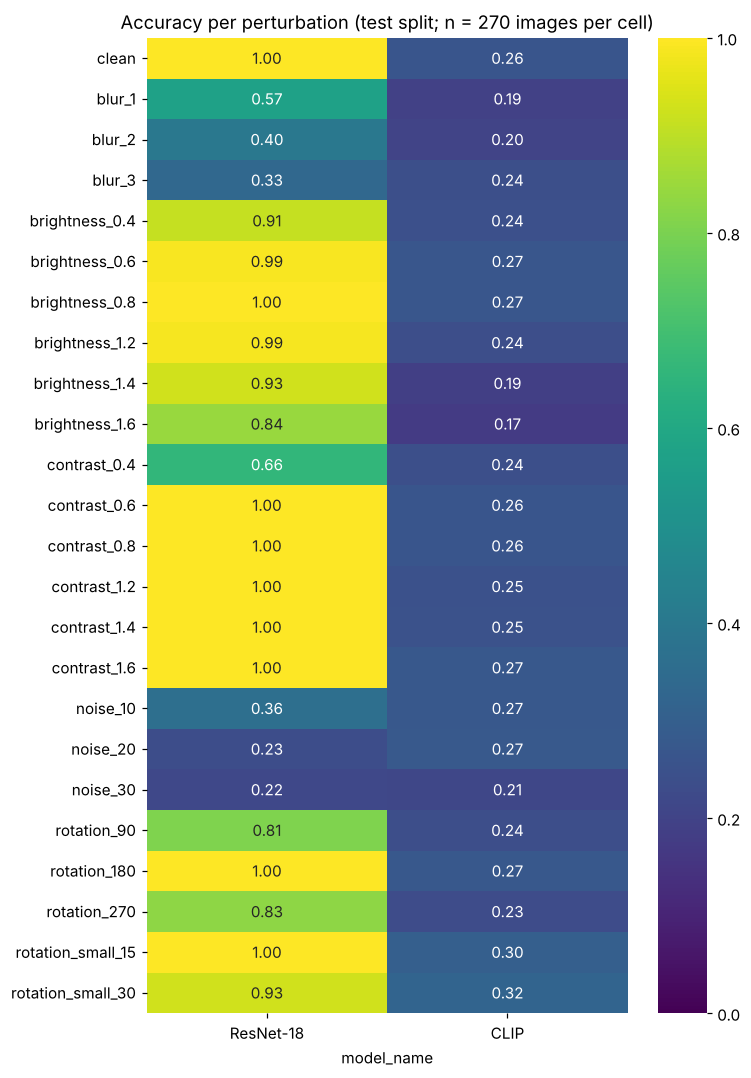

In [2]:
acc = both.pivot_table(index='cond', columns='model_name', values='correct', aggfunc='mean').loc[cond_order]
acc['drop_resnet'] = acc.loc['clean', 'ResNet-18'] - acc['ResNet-18']

fig, ax = plt.subplots(figsize=(7, 0.35*len(acc)+1.5))
sns.heatmap(acc[['ResNet-18', 'CLIP']], annot=True, fmt='.2f', cmap='viridis', vmin=0, vmax=1, ax=ax)
ax.set_title('Accuracy per perturbation (test split; n = 270 images per cell)')
ax.set_ylabel('')
plt.tight_layout(); plt.savefig('accuracy_by_perturbation.png', dpi=300); plt.show()

print(acc[['ResNet-18','CLIP']].round(3).to_string())
print('Worst 5 ResNet-18:'); print(acc['ResNet-18'].nsmallest(5).round(3))

## 2. WHERE inside the data? (class x perturbation)
**Question:** when ResNet-18 breaks, do all classes break or only some?

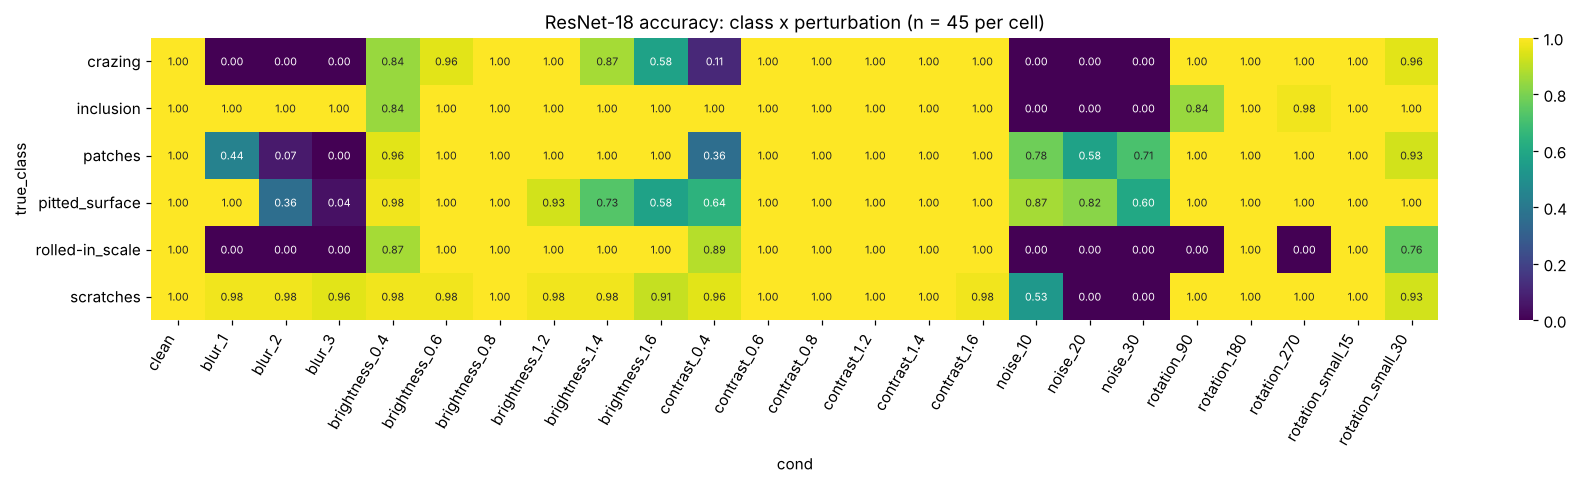

In [3]:
order = cond_order
piv = res.pivot_table(index='true_class', columns='cond', values='correct', aggfunc='mean')[order]

fig, ax = plt.subplots(figsize=(0.55*len(order)+3, 4.5))
sns.heatmap(piv, annot=True, fmt='.2f', annot_kws={'size': 7}, cmap='viridis', vmin=0, vmax=1, ax=ax)
ax.set_title('ResNet-18 accuracy: class x perturbation (n = 45 per cell)')
plt.xticks(rotation=60, ha='right'); plt.tight_layout()
plt.savefig('resnet_class_by_perturbation.png', dpi=300); plt.show()

## 3. WHY? Does confidence separate right from wrong?
**Question:** is the model's confidence informative about its own mistakes? (open question from the midpoint reflection)
Each dot is one image. Confidence of correct vs wrong predictions, over all conditions.

                    count   mean  median
model_name outcome                      
CLIP       correct   1598  0.475   0.448
           wrong     4882  0.460   0.436
ResNet-18  correct   5130  0.940   0.996
           wrong     1350  0.511   0.410


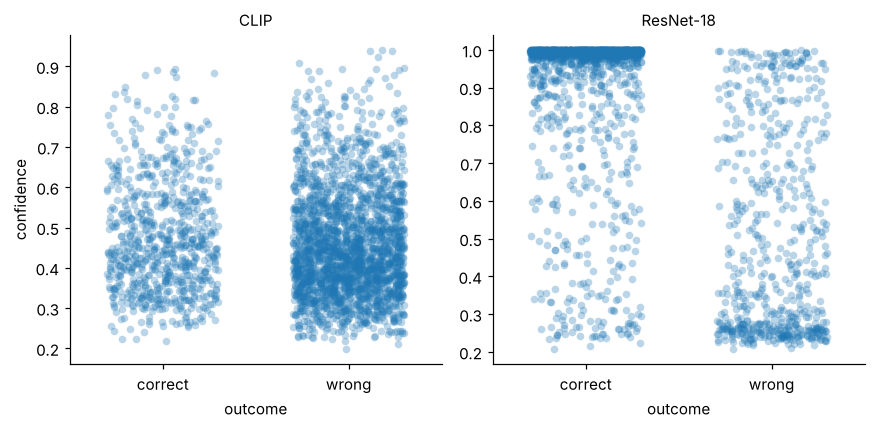

In [4]:
both['outcome'] = both['correct'].map({1: 'correct', 0: 'wrong'})
g = sns.catplot(data=both.sample(min(len(both), 6000), random_state=0), x='outcome', y='confidence',
                col='model_name', kind='strip', alpha=0.3, jitter=0.3, sharey=False, height=4, order=['correct', 'wrong'])
g.set_titles('{col_name}')
plt.savefig('confidence_correct_vs_wrong.png', dpi=300); plt.show()

print(both.groupby(['model_name', 'outcome'])['confidence'].agg(['count', 'mean', 'median']).round(3))

## 4. WHY (CLIP)? What does CLIP predict instead?
**Question:** is CLIP's bias toward a few classes (e.g. scratches) specific to clean images, or does it
stay when images are perturbed? Share of each predicted class, per perturbation.

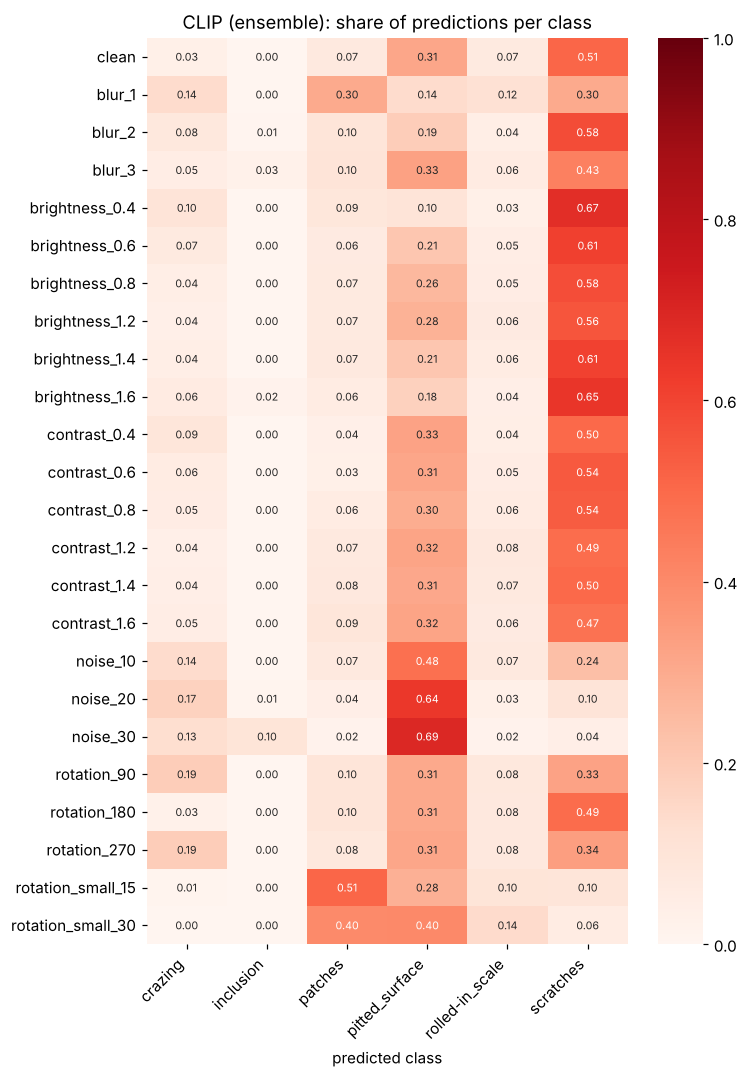

In [5]:
share = (clip.groupby(['cond', 'pred_class']).size()
             .unstack(fill_value=0))
share = share.div(share.sum(axis=1), axis=0).reindex(columns=classes, fill_value=0).loc[order]

fig, ax = plt.subplots(figsize=(7, 0.35*len(share)+1.5))
sns.heatmap(share, annot=True, fmt='.2f', annot_kws={'size': 7}, cmap='Reds', vmin=0, vmax=1, ax=ax)
ax.set_title(f'CLIP ({CLIP_PROMPT_SET}): share of predictions per class')
ax.set_ylabel(''); ax.set_xlabel('predicted class')
plt.xticks(rotation=45, ha='right'); plt.tight_layout()
plt.savefig('clip_prediction_share.png', dpi=300); plt.show()

## 5. STABLE? Does the CLIP result depend on the prompt set?
**Question:** the midpoint used only the ensemble prompts. Does accuracy and the "scratches" bias change with the other three?

share of "scratches" predictions per prompt set:
prompt_set
defect      0.296
ensemble    0.511
plain       0.089
steel       0.052
Name: pred_class, dtype: float64


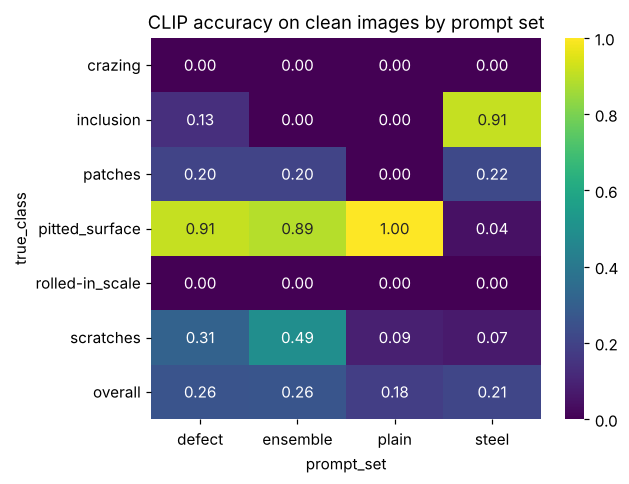

In [6]:
clip_all = df[(df['model'] == 'CLIP-ViT-B32') & (df['cond'] == 'clean')]
pa = clip_all.pivot_table(index='true_class', columns='prompt_set', values='correct', aggfunc='mean')
pa.loc['overall'] = clip_all.groupby('prompt_set')['correct'].mean()

fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(pa, annot=True, fmt='.2f', cmap='viridis', vmin=0, vmax=1, ax=ax)
ax.set_title('CLIP accuracy on clean images by prompt set')
plt.tight_layout(); plt.savefig('clip_prompt_sets.png', dpi=300); plt.show()

sc = clip_all.groupby('prompt_set')['pred_class'].apply(lambda s: (s == 'scratches').mean())
print('share of "scratches" predictions per prompt set:'); print(sc.round(3))

## 6. Fixed versions of the midpoint plots (technical issues only)
KDE: separate panels so CLIP is not flattened by ResNet's spike. Bars: values written on bars (zero is visible), legend outside.

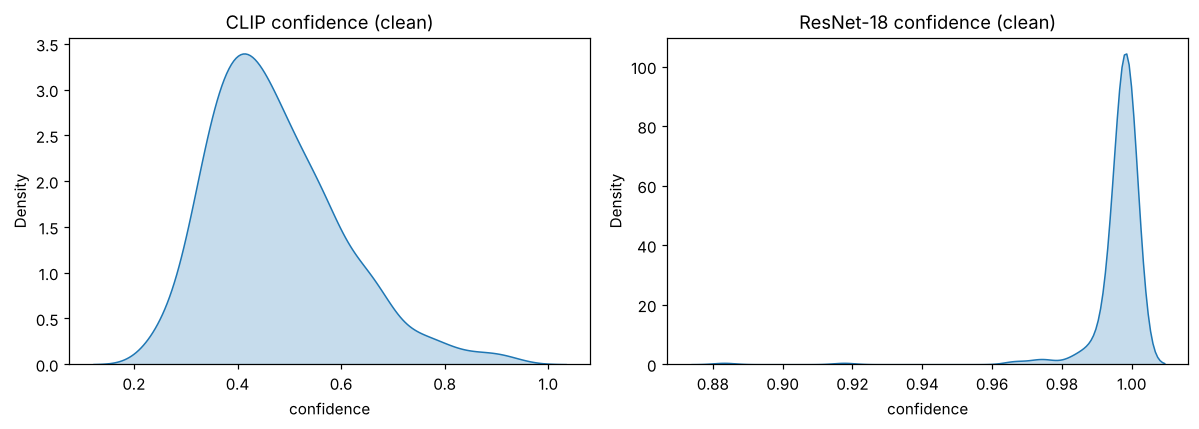

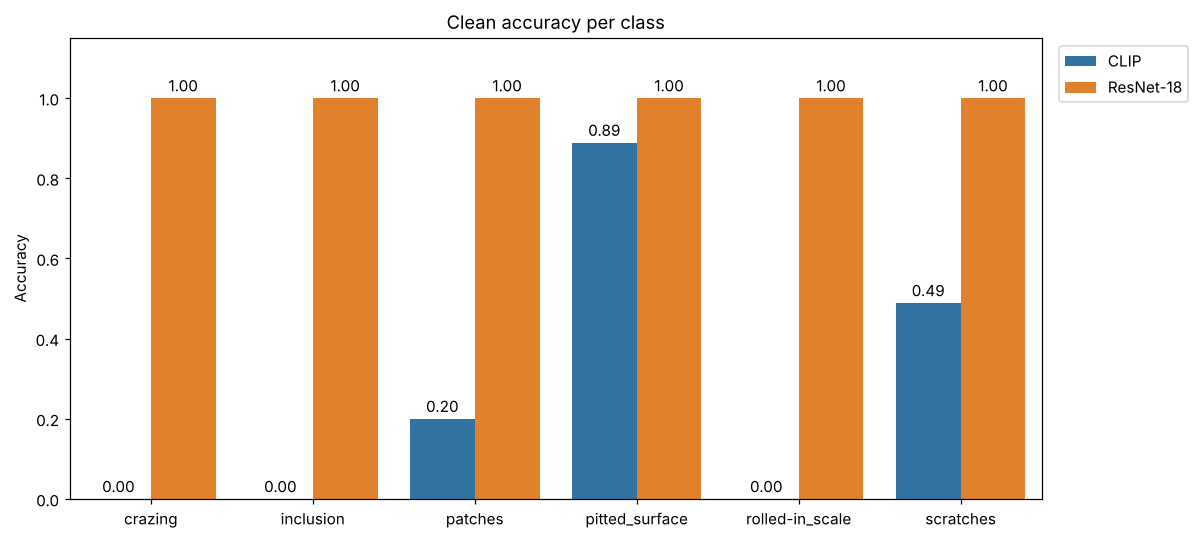

In [7]:
clean = both[both['cond'] == 'clean']

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, sub) in zip(axes, clean.groupby('model_name')):
    sns.kdeplot(sub['confidence'], fill=True, ax=ax, warn_singular=False)
    ax.set_title(f'{name} confidence (clean)'); ax.set_xlabel('confidence')
plt.tight_layout(); plt.savefig('confidence_distribution_fixed.png', dpi=300); plt.show()

ca = clean.pivot_table(index='true_class', columns='model_name', values='correct', aggfunc='mean') \
          .reset_index().melt(id_vars='true_class', var_name='Model', value_name='Accuracy')
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(data=ca, x='true_class', y='Accuracy', hue='Model', ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt='%.2f', padding=2)
ax.set_ylim(0, 1.15); ax.set_xlabel('')
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
ax.set_title('Clean accuracy per class')
plt.tight_layout(); plt.savefig('class_accuracy_fixed.png', dpi=300); plt.show()